# OLA Ride Insights | End-to-End Analysis

**Senior analyst working notebook** ? Source review ? Data quality ? Cleaning ? Feature engineering ? EDA ? Business recommendations

> **Analysis grain:** one source row per booking. **Coverage:** July 2024 only. **Purpose:** establish a transparent baseline for booking conversion, supply fulfillment, ride mix and customer experience.

## Contents

1. [Business framing and metric contract](#1-business-framing-and-metric-contract)
2. [Load and understand the source](#2-load-and-understand-the-source)
3. [Data quality and cleaning](#3-data-quality-and-cleaning)
4. [Feature engineering and analytical dataset](#4-feature-engineering-and-analytical-dataset)
5. [Decision metrics](#5-decision-metrics)
6. [Exploratory analysis (UBM)](#6-exploratory-analysis-ubm)
7. [Findings, actions and limitations](#7-findings-actions-and-limitations)

Run from the project root after installing `requirements.txt`. Cells are intentionally output-light; charts and tables are computed from the supplied workbook. The production cleaning logic is reused from `src/ola_ride_insights/pipeline.py` so the notebook and application share definitions.

## 1. Business framing and metric contract

### Decision questions

- How many bookings convert to successful rides, and where does demand fail?
- Which vehicle, pickup zone and booking hours carry the most demand or unmet demand?
- How do recorded booking value and ride distance vary by outcome, payment method and vehicle?
- What do observed ratings show, and how much feedback is available to support comparison?

### Definitions fixed before analysis

| Measure | Definition | Guardrail |
|---|---|---|
| Booking conversion | `Success` bookings / all in-scope bookings | Descriptive baseline; no prior period for comparison |
| Customer cancellation rate | `Canceled by Customer` / all bookings | Uses exact normalized status |
| Driver cancellation rate | `Canceled by Driver` / all bookings | Kept distinct from driver not found |
| Driver-not-found rate | `Driver Not Found` / all bookings | Unfulfilled supply outcome, not a cancellation |
| Completed booking value | Sum of `Booking_Value` for `Success` only | Source units and accounting recognition are unknown |
| Rating average | Mean of non-null observed ratings | Missing feedback remains missing, never zero-filled |

**Scope boundary:** this is a descriptive analysis, not a causal evaluation. The workbook has one month, no cost or margin fields, no surge indicator, and no driver-hours or customer-demographic data.

## 2. Load and understand the source

Load the first worksheet unchanged, identify project paths, and record the source shape, fields and grain before transformation.\n\n**Provenance:** data/OLA_DataSet.xlsx (first worksheet) -> shared clean transformation -> in-memory analysis frame. The workbook is preserved; the reproducible processed CSV is written by the project pipeline.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Find the repository root whether Jupyter starts here or in notebooks/.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "src/ola_ride_insights/pipeline.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter from the project root or a subfolder of it.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ola_ride_insights.pipeline import clean, completed_distance_quartiles, mapping, read_source

SOURCE_PATH = ROOT / "data/OLA_DataSet.xlsx"
assert SOURCE_PATH.exists(), f"Source workbook not found: {SOURCE_PATH}"

sns.set_theme(style="whitegrid", palette=["#7D9400", "#171717", "#D7DF23", "#66705D", "#E89E25"])
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

raw = read_source(SOURCE_PATH)
source_fields = mapping(raw.columns)
print(f"Source: {SOURCE_PATH.relative_to(ROOT)} | {len(raw):,} rows ? {raw.shape[1]} columns")
print("Working grain: one source record per booking; booking-ID uniqueness is checked below.")
display(raw.head(5))

Source: data\OLA_DataSet.xlsx | 103,024 rows ? 20 columns
Working grain: one source record per booking; booking-ID uniqueness is checked below.


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


In [2]:
source_profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "distinct": raw.nunique(dropna=True),
}).sort_values(["missing_pct", "distinct"], ascending=[False, True])

display(source_profile)
print("Exact duplicate rows:", f"{raw.duplicated().sum():,}")
booking_id_col = source_fields.get("booking_id")
print("Duplicate booking IDs:", f"{raw[booking_id_col].duplicated().sum():,}" if booking_id_col else "Booking ID field not found")

,dtype,non_null,missing,missing_pct,distinct
Incomplete_Rides_Reason,object,3926,99098,96.19,3
Canceled_Rides_by_Customer,object,10499,92525,89.81,5
Canceled_Rides_by_Driver,object,18434,84590,82.11,4
Incomplete_Rides,object,63967,39057,37.91,2
Payment_Method,object,63967,39057,37.91,4
Driver_Ratings,float64,63967,39057,37.91,21
Customer_Rating,float64,63967,39057,37.91,21
C_TAT,float64,63967,39057,37.91,25
V_TAT,float64,63967,39057,37.91,40
Booking_Status,object,103024,0,0.00,4


Exact duplicate rows: 0
Duplicate booking IDs: 0


### Source profile and risks

Use this profile to distinguish missingness, duplicate rows and identifier reuse. Cancellation reason columns are descriptive text; they are not boolean flags. Confirm actual status labels and numeric ranges before choosing metrics.

In [3]:
status_col = source_fields.get("booking_status")
if status_col:
    status_profile = raw[status_col].value_counts(dropna=False).rename_axis("Source status").to_frame("Bookings")
    status_profile["Share (%)"] = (status_profile["Bookings"] / len(raw) * 100).round(2)
    display(status_profile)

numeric_source = raw.select_dtypes(include="number")
if not numeric_source.empty:
    display(numeric_source.describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2))

for key in ("customer_rating", "driver_rating", "ride_distance", "booking_value", "booking_id"):
    column = source_fields.get(key)
    if column:
        print(f"{column}: {raw[column].nunique(dropna=True):,} non-null distinct values; {raw[column].isna().sum():,} missing")

,Bookings,Share (%)
Source status,,
Success,63967,62.09
Canceled by Driver,18434,17.89
Canceled by Customer,10499,10.19
Driver Not Found,10124,9.83


,count,mean,std,min,1%,25%,50%,75%,99%,max
V_TAT,63967.0,170.88,80.80,35.0,35.0,98.0,168.0,238.0,308.0,308.0
C_TAT,63967.0,84.87,36.01,25.0,25.0,55.0,85.0,115.0,145.0,145.0
Booking_Value,103024.0,548.75,536.54,100.0,105.0,242.0,386.0,621.0,2780.0,2999.0
Ride_Distance,103024.0,14.19,15.78,0.0,0.0,0.0,8.0,26.0,49.0,49.0
Driver_Ratings,63967.0,4.00,0.58,3.0,3.0,3.5,4.0,4.5,5.0,5.0
Customer_Rating,63967.0,4.00,0.58,3.0,3.0,3.5,4.0,4.5,5.0,5.0


Customer_Rating: 21 non-null distinct values; 39,057 missing
Driver_Ratings: 21 non-null distinct values; 39,057 missing
Ride_Distance: 50 non-null distinct values; 0 missing
Booking_Value: 2,883 non-null distinct values; 0 missing
Booking_ID: 103,024 non-null distinct values; 0 missing


## 3. Data quality and cleaning

Apply the project cleaning function and keep the raw frame intact. The shared policy trims text whitespace, coerces analytical measures, parses booking date/time, adds outcome and calendar fields, removes exact duplicate rows only, and excludes the workbook's presentation-only vehicle-image field. It does **not** impute ratings or delete statistical outliers.

In [4]:
df, fields, cleaning_audit = clean(raw)
print(f"Raw rows: {len(raw):,} | Cleaned rows: {len(df):,} | Retained columns: {df.shape[1]}")
display(cleaning_audit)
assert len(df) == len(raw) - int(raw.duplicated().sum()), "Unexpected row-count change in cleaning."

Raw rows: 103,024 | Cleaned rows: 103,024 | Retained columns: 33


,action,count,policy
0,exact duplicate rows removed,0,confirmed exact duplicate only
1,rows with duplicate booking ID,0,retained for investigation; not assumed duplic...
2,presentation-only icon columns excluded,1,source workbook remains unchanged


In [5]:
# Re-check critical quality conditions after cleaning.
quality_checks = []
for key, label, condition in [
    ("booking_id", "Missing booking identifier", "missing"),
    ("booking_status", "Missing booking status", "missing"),
    ("booking_value", "Negative booking value", "negative"),
    ("ride_distance", "Negative source ride distance", "negative"),
    ("customer_rating", "Customer rating outside 0?5", "rating"),
    ("driver_rating", "Driver rating outside 0?5", "rating"),
]:
    col = fields.get(key)
    if not col or col not in df:
        continue
    values = pd.to_numeric(df[col], errors="coerce") if condition in {"negative", "rating"} else df[col]
    if condition == "missing":
        count = int(values.isna().sum())
    elif condition == "negative":
        count = int((values < 0).sum())
    else:
        count = int((values.notna() & ~values.between(0, 5)).sum())
    quality_checks.append({"Check": label, "Rows flagged": count, "Treatment": "Review; no silent correction"})

quality_table = pd.DataFrame(quality_checks)
display(quality_table)

status = df[fields["booking_status"]].astype("string").str.strip().str.casefold()
print("Observed cleaned statuses:", ", ".join(sorted(status.dropna().unique())))
print("Missing customer ratings retained:", f"{df[fields['customer_rating']].isna().sum():,}" if fields.get("customer_rating") else "field unavailable")
print("Missing driver ratings retained:", f"{df[fields['driver_rating']].isna().sum():,}" if fields.get("driver_rating") else "field unavailable")

# Successful trips must have a valid positive travelled distance; zero distances
# on unsuccessful outcomes are expected source placeholders, not trips.
success_mask = df[fields["booking_status"]].astype("string").str.strip().str.casefold().eq("success")
completed_distance = pd.to_numeric(df.loc[success_mask, fields["ride_distance"]], errors="coerce")
invalid_completed_distance = int((completed_distance.isna() | completed_distance.le(0)).sum())
quality_table = pd.concat([quality_table, pd.DataFrame([{
    "Check": "Successful booking distance missing or zero",
    "Rows flagged": invalid_completed_distance,
    "Treatment": "Completed-trip distance uses Success rows only",
}])], ignore_index=True)
display(quality_table.tail(1))
assert int(success_mask.sum()) == 63_967
assert int((~success_mask).sum()) == 39_057
assert invalid_completed_distance == 0
print(f"Completed-trip distance validation passed: {success_mask.sum():,} successful; {completed_distance.mean():.2f} mean source units; no missing/zero/negative distances.")
print(f"Unsuccessful rows retained in the analytical frame: {(~success_mask).sum():,}; their zero distances are excluded from completed-trip analyses.")


,Check,Rows flagged,Treatment
0,Missing booking identifier,0,Review; no silent correction
1,Missing booking status,0,Review; no silent correction
2,Negative booking value,0,Review; no silent correction
3,Negative source ride distance,0,Review; no silent correction
4,Customer rating outside 0?5,0,Review; no silent correction
5,Driver rating outside 0?5,0,Review; no silent correction


Observed cleaned statuses: canceled by customer, canceled by driver, driver not found, success
Missing customer ratings retained: 39,057
Missing driver ratings retained: 39,057


,Check,Rows flagged,Treatment
6,Successful booking distance missing or zero,0,Completed-trip distance uses Success rows only


Completed-trip distance validation passed: 63,967 successful; 22.85 mean source units; no missing/zero/negative distances.
Unsuccessful rows retained in the analytical frame: 39,057; their zero distances are excluded from completed-trip analyses.


### Cleaning decisions

- Exact duplicate rows are removed because every field matches; duplicate booking IDs are reported separately and retained for investigation.
- Missing ratings are not zeros and are not imputed. Rating comparisons include observed feedback only and report coverage.
- IQR outliers are review candidates, not automatic errors. The source units and business limits are not documented.
- Parsed timestamps and derived flags preserve a traceable path back to source fields.

## 4. Feature engineering and analytical dataset

The shared pipeline provides booking datetime, exact status flags, calendar parts, weekday/weekend and time-of-day. Add two analysis-only features for fairer trip-distance segmentation and paired-feedback review; these do not replace source fields.

In [6]:
# Rebuild normalized status once for analysis; source status values remain in df.
status = df[fields["booking_status"]].astype("string").str.strip().str.casefold()
df["_status_norm"] = status
_status_norm = df["_status_norm"]
vehicle_col = fields.get("vehicle_type")

# Quartiles are computed only from successful bookings. Tied cut points collapse;
# equal distances are never split, and unsuccessful/missing-distance rows stay null.
distance_col = fields.get("ride_distance")
if distance_col:
    df["Ride Distance Quartile"] = completed_distance_quartiles(
        df, fields.get("booking_status"), distance_col
    )

# Paired rating features exist only when both source ratings were observed.
customer_rating_col = fields.get("customer_rating")
driver_rating_col = fields.get("driver_rating")
if customer_rating_col and driver_rating_col:
    customer_rating = pd.to_numeric(df[customer_rating_col], errors="coerce")
    driver_rating = pd.to_numeric(df[driver_rating_col], errors="coerce")
    paired = customer_rating.notna() & driver_rating.notna()
    df["Paired Rating Feedback"] = paired
    df["Customer minus Driver Rating"] = (customer_rating - driver_rating).where(paired)

engineered = [c for c in ["Booking DateTime", "Successful Booking Flag", "Customer Cancellation Flag", "Driver Cancellation Flag", "Cancellation Flag", "Incomplete Flag", "Booking Hour", "Day of Week", "Weekday/Weekend", "Time of Day", "Ride Distance Quartile", "Paired Rating Feedback", "Customer minus Driver Rating"] if c in df]
print(f"Analytical frame: {df.shape[0]:,} rows ? {df.shape[1]} columns")
display(pd.DataFrame({"Feature": engineered, "Definition": [
    "Parsed source date and time" if c == "Booking DateTime" else
    "Booking outcome / calendar feature from the shared pipeline" if c not in {"Ride Distance Quartile", "Paired Rating Feedback", "Customer minus Driver Rating"} else
    "Tie-safe completed-trip distance band; unsuccessful and missing-distance rows are unclassified" if c == "Ride Distance Quartile" else
    "Both customer and driver ratings are observed" if c == "Paired Rating Feedback" else
    "Customer rating minus driver rating, paired records only"
    for c in engineered
]}))

Analytical frame: 103,024 rows ? 36 columns


,Feature,Definition
0,Booking DateTime,Parsed source date and time
1,Successful Booking Flag,Booking outcome / calendar feature from the sh...
2,Customer Cancellation Flag,Booking outcome / calendar feature from the sh...
3,Driver Cancellation Flag,Booking outcome / calendar feature from the sh...
4,Cancellation Flag,Booking outcome / calendar feature from the sh...
5,Incomplete Flag,Booking outcome / calendar feature from the sh...
6,Booking Hour,Booking outcome / calendar feature from the sh...
7,Day of Week,Booking outcome / calendar feature from the sh...
8,Weekday/Weekend,Booking outcome / calendar feature from the sh...
9,Time of Day,Booking outcome / calendar feature from the sh...


### Feature engineering validation

Check every derived feature against its source definition. The table reports records checked, passed and failed; assertions below make unexpected classifications stop the notebook. `Ride Distance Quartile` is recalculated by the shared pipeline helper, uses successful bookings only, collapses tied cut points and leaves unsuccessful or missing-distance records unclassified.

In [7]:
# Reconstruct source-derived values independently, then compare row by row.
source_rows = raw.loc[df.index]
validation_status = source_rows[fields["booking_status"]].astype("string").str.strip().str.casefold()
source_dates = pd.to_datetime(source_rows[fields["date"]], errors="coerce", dayfirst=True)
source_times = pd.to_timedelta(source_rows[fields["time"]].astype(str), errors="coerce")
expected_datetime = source_dates.dt.normalize() + source_times
expected_hour = expected_datetime.dt.hour
expected_status_flags = {
    "Successful Booking Flag": validation_status.eq("success").astype("int8"),
    "Customer Cancellation Flag": validation_status.eq("canceled by customer").astype("int8"),
    "Driver Cancellation Flag": validation_status.eq("canceled by driver").astype("int8"),
    "Cancellation Flag": validation_status.str.startswith("canceled", na=False).astype("int8"),
    "Incomplete Flag": source_rows[fields["incomplete"]].astype("string").str.strip().str.casefold().eq("yes").fillna(False).astype("int8"),
}

validation_rows = []
def validate_feature(name, rule, actual, expected, mask=None, numeric=False):
    actual = pd.Series(actual, index=df.index)
    expected = pd.Series(expected, index=df.index)
    checked = pd.Series(True, index=df.index) if mask is None else pd.Series(mask, index=df.index).fillna(False).astype(bool)
    if numeric:
        actual_values = pd.to_numeric(actual, errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
        expected_values = pd.to_numeric(expected, errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
        matches = pd.Series(np.isclose(actual_values, expected_values, rtol=0, atol=1e-9, equal_nan=True), index=df.index)
    else:
        same = actual.astype("string").eq(expected.astype("string")).fillna(False)
        matches = same | (actual.isna() & expected.isna())
    records = int(checked.sum())
    failed = int((checked & ~matches).sum())
    validation_rows.append({
        "Feature": name, "Validation rule": rule, "Records checked": records,
        "Passed": records - failed, "Failed": failed,
        "Status": "PASS" if failed == 0 else "FAIL",
    })

validate_feature("Booking DateTime", "Parsed source Date plus Time equals reconstructed timestamp", df["Booking DateTime"], expected_datetime)
for name, expected in expected_status_flags.items():
    validate_feature(name, f"Matches normalized source status / incomplete flag: {name}", df[name], expected)
validate_feature("Booking Year", "Calendar year from reconstructed Booking DateTime", df["Booking Year"], expected_datetime.dt.year)
validate_feature("Booking Month", "Calendar month from reconstructed Booking DateTime", df["Booking Month"], expected_datetime.dt.month)
validate_feature("Booking Day", "Day of month from reconstructed Booking DateTime", df["Booking Day"], expected_datetime.dt.day)
validate_feature("Booking Hour", "Hour from reconstructed Booking DateTime", df["Booking Hour"], expected_hour)
validate_feature("Day of Week", "Weekday name from reconstructed Booking DateTime", df["Day of Week"], expected_datetime.dt.day_name())
expected_weekpart = pd.Series(np.where(expected_datetime.dt.dayofweek >= 5, "Weekend", "Weekday"), index=df.index).where(expected_datetime.notna())
validate_feature("Weekday/Weekend", "Weekend iff reconstructed weekday is Saturday or Sunday", df["Weekday/Weekend"], expected_weekpart)
expected_time_of_day = pd.cut(expected_hour, [-1, 5, 11, 16, 20, 24], labels=["Night", "Morning", "Afternoon", "Evening", "Late evening"]).astype("string")
validate_feature("Time of Day", "Time band matches reconstructed Booking DateTime hour", df["Time of Day"], expected_time_of_day)

expected_quartiles = completed_distance_quartiles(df, fields["booking_status"], fields["ride_distance"])
validate_feature("Ride Distance Quartile", "Tie-safe quartiles from successful observed distances only", df["Ride Distance Quartile"], expected_quartiles)
non_success = ~validation_status.eq("success")
quartile_leakage = df["Ride Distance Quartile"].notna() & non_success
validation_rows.append({
    "Feature": "Ride Distance Quartile population",
    "Validation rule": "No unsuccessful booking receives a completed-trip distance band",
    "Records checked": len(df), "Passed": len(df) - int(quartile_leakage.sum()),
    "Failed": int(quartile_leakage.sum()), "Status": "PASS" if not quartile_leakage.any() else "FAIL",
})
quartile_reproducible = df["Ride Distance Quartile"].fillna("<NA>").equals(expected_quartiles.fillna("<NA>"))
validation_rows.append({
    "Feature": "Ride Distance Quartile reproducibility",
    "Validation rule": "Repeated calculation gives identical row-level bands",
    "Records checked": len(df), "Passed": len(df) if quartile_reproducible else 0,
    "Failed": 0 if quartile_reproducible else len(df), "Status": "PASS" if quartile_reproducible else "FAIL",
})

customer_rating = pd.to_numeric(df[fields["customer_rating"]], errors="coerce")
driver_rating = pd.to_numeric(df[fields["driver_rating"]], errors="coerce")
expected_paired = customer_rating.notna() & driver_rating.notna()
validate_feature("Paired Rating Feedback", "True only when both source ratings are observed", df["Paired Rating Feedback"], expected_paired)
expected_rating_gap = (customer_rating - driver_rating).where(expected_paired)
validate_feature("Customer Minus Driver Rating", "Customer rating minus driver rating on paired feedback", df["Customer minus Driver Rating"], expected_rating_gap, numeric=True)

flags = df[["Successful Booking Flag", "Customer Cancellation Flag", "Driver Cancellation Flag"]].sum(axis=1)
flag_overlap = flags.gt(1)
validation_rows.append({
    "Feature": "Outcome flag exclusivity",
    "Validation rule": "A booking cannot be successful and canceled, or customer- and driver-canceled simultaneously",
    "Records checked": len(df), "Passed": len(df) - int(flag_overlap.sum()),
    "Failed": int(flag_overlap.sum()), "Status": "PASS" if not flag_overlap.any() else "FAIL",
})

feature_validation = pd.DataFrame(validation_rows)
display(feature_validation)

expected_counts = {
    "successful": 63_967,
    "customer_cancelled": 10_499,
    "driver_cancelled": 18_434,
    "incomplete": 3_926,
}
actual_counts = {
    "successful": int(expected_status_flags["Successful Booking Flag"].sum()),
    "customer_cancelled": int(expected_status_flags["Customer Cancellation Flag"].sum()),
    "driver_cancelled": int(expected_status_flags["Driver Cancellation Flag"].sum()),
    "incomplete": int(expected_status_flags["Incomplete Flag"].sum()),
}
assert actual_counts == expected_counts, f"Source outcome counts changed: {actual_counts}"
assert invalid_completed_distance == 0, f"Found {invalid_completed_distance} successful rows with missing/nonpositive distance."
assert (feature_validation["Status"] == "PASS").all(), feature_validation.loc[feature_validation["Status"] != "PASS"]
print("Outcome counts validated:", actual_counts)
print(f"Feature checks: {len(feature_validation)} passed rows; {int(feature_validation['Failed'].sum())} failed comparisons.")

,Feature,Validation rule,Records checked,Passed,Failed,Status
0,Booking DateTime,Parsed source Date plus Time equals reconstruc...,103024,103024,0,PASS
1,Successful Booking Flag,Matches normalized source status / incomplete ...,103024,103024,0,PASS
2,Customer Cancellation Flag,Matches normalized source status / incomplete ...,103024,103024,0,PASS
3,Driver Cancellation Flag,Matches normalized source status / incomplete ...,103024,103024,0,PASS
4,Cancellation Flag,Matches normalized source status / incomplete ...,103024,103024,0,PASS
5,Incomplete Flag,Matches normalized source status / incomplete ...,103024,103024,0,PASS
6,Booking Year,Calendar year from reconstructed Booking DateTime,103024,103024,0,PASS
7,Booking Month,Calendar month from reconstructed Booking Date...,103024,103024,0,PASS
8,Booking Day,Day of month from reconstructed Booking DateTime,103024,103024,0,PASS
9,Booking Hour,Hour from reconstructed Booking DateTime,103024,103024,0,PASS


Outcome counts validated: {'successful': 63967, 'customer_cancelled': 10499, 'driver_cancelled': 18434, 'incomplete': 3926}
Feature checks: 19 passed rows; 0 failed comparisons.


## 5. Decision metrics

Use all in-scope bookings as the denominator for outcome rates. Keep supply cancellations, customer cancellations and driver-not-found outcomes separate. Treat completed value as a source booking measure, not audited revenue.

In [8]:
n_bookings = len(df)
is_success = status.eq("success")
is_customer_cancel = status.eq("canceled by customer")
is_driver_cancel = status.eq("canceled by driver")
is_driver_not_found = status.eq("driver not found")
is_incomplete = df[fields["incomplete"]].astype("string").str.strip().str.casefold().eq("yes") if fields.get("incomplete") else pd.Series(False, index=df.index)

value_col = fields.get("booking_value")
metrics = [
    ("Bookings in scope", n_bookings, "All cleaned booking rows"),
    ("Successful rides", int(is_success.sum()), "Status = Success"),
    ("Booking conversion", is_success.mean(), "Successful / all bookings"),
    ("Customer cancellation rate", is_customer_cancel.mean(), "Customer cancellations / all bookings"),
    ("Driver cancellation rate", is_driver_cancel.mean(), "Driver cancellations / all bookings"),
    ("Driver-not-found rate", is_driver_not_found.mean(), "Driver not found / all bookings"),
    ("Source-flagged incomplete rides", int(is_incomplete.sum()), "Incomplete_Rides = Yes; separate from status"),
]
if value_col:
    completed_value = pd.to_numeric(df.loc[is_success, value_col], errors="coerce").sum()
    metrics.append(("Completed booking value", completed_value, "Successful bookings only; source units"))
metric_table = pd.DataFrame(metrics, columns=["Metric", "Value", "Definition"])
metric_table["Value"] = metric_table.apply(lambda row: f"{row.Value:.1%}" if "rate" in row.Metric.lower() or row.Metric == "Booking conversion" else f"{row.Value:,.0f}", axis=1)
display(metric_table)

,Metric,Value,Definition
0,Bookings in scope,"103,024",All cleaned booking rows
1,Successful rides,"63,967",Status = Success
2,Booking conversion,62.1%,Successful / all bookings
3,Customer cancellation rate,10.2%,Customer cancellations / all bookings
4,Driver cancellation rate,17.9%,Driver cancellations / all bookings
5,Driver-not-found rate,9.8%,Driver not found / all bookings
6,Source-flagged incomplete rides,"3,926",Incomplete_Rides = Yes; separate from status
7,Completed booking value,"35,080,467",Successful bookings only; source units


## 6. Exploratory analysis (UBM)

**UBM structure:** univariate analysis describes each field, bivariate analysis compares two measures or groups, and multivariate analysis examines several operational dimensions together. Every result below is descriptive and interpreted within the July 2024 source scope.

### 6.1 Univariate | Volume, mix and distributions

Start with one variable at a time: booking outcome, vehicle mix, booking hour, ride distance, booking value and observed rating distributions. Numeric labels retain source units where those units are unknown.

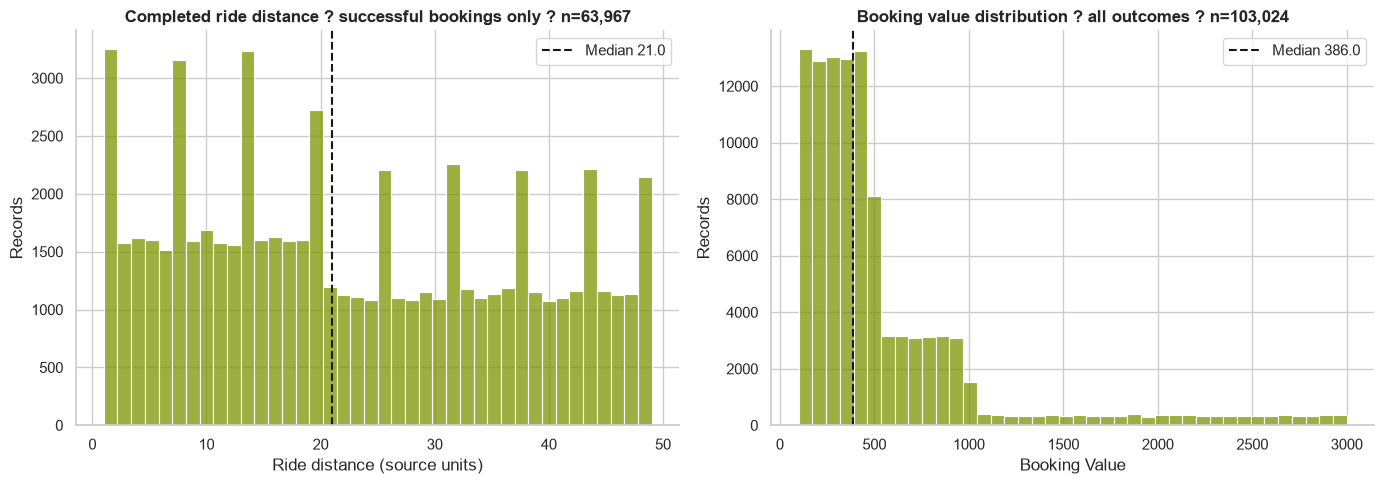

Completed ride-distance mean: 22.85 source units.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, key, title in [
    (axes[0], "ride_distance", "Completed ride distance ? successful bookings only"),
    (axes[1], "booking_value", "Booking value distribution ? all outcomes"),
]:
    col = fields.get(key)
    if col:
        population = df.loc[_status_norm.eq("success"), col] if key == "ride_distance" else df[col]
        values = pd.to_numeric(population, errors="coerce").dropna()
        if key == "ride_distance":
            assert values.gt(0).all(), "Successful trip-distance analysis must exclude invalid/nonpositive distances."
        sns.histplot(values, bins=40, ax=ax, color="#7D9400")
        ax.axvline(values.median(), color="#171717", linestyle="--", label=f"Median {values.median():,.1f}")
        ax.set(title=f"{title} ? n={len(values):,}", xlabel="Ride distance (source units)" if key == "ride_distance" else col.replace("_", " "), ylabel="Records")
        ax.legend()
plt.tight_layout()
plt.show()
print(f"Completed ride-distance mean: {df.loc[_status_norm.eq('success'), fields['ride_distance']].mean():.2f} source units.")

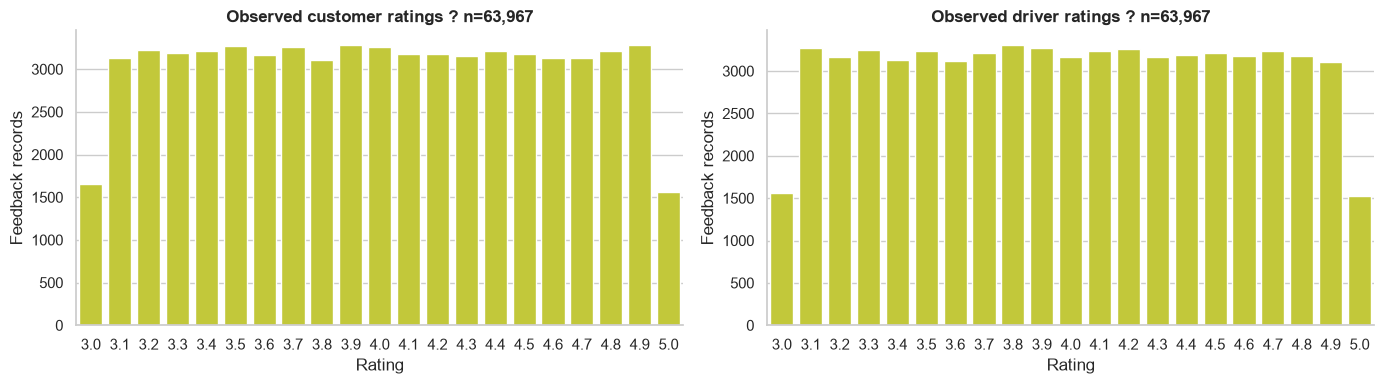

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, key, title in [
    (axes[0], "customer_rating", "Observed customer ratings"),
    (axes[1], "driver_rating", "Observed driver ratings"),
]:
    col = fields.get(key)
    if col:
        values = pd.to_numeric(df[col], errors="coerce").dropna()
        sns.countplot(x=values, ax=ax, color="#D7DF23")
        ax.set(title=f"{title} ? n={len(values):,}", xlabel="Rating", ylabel="Feedback records")
plt.tight_layout()
plt.show()

### 6.2 Bivariate | Time, outcomes, vehicle, value and feedback

Compare booking volume over time and weekday/hour patterns. The source spans a single month, so these charts show within-month variation only.

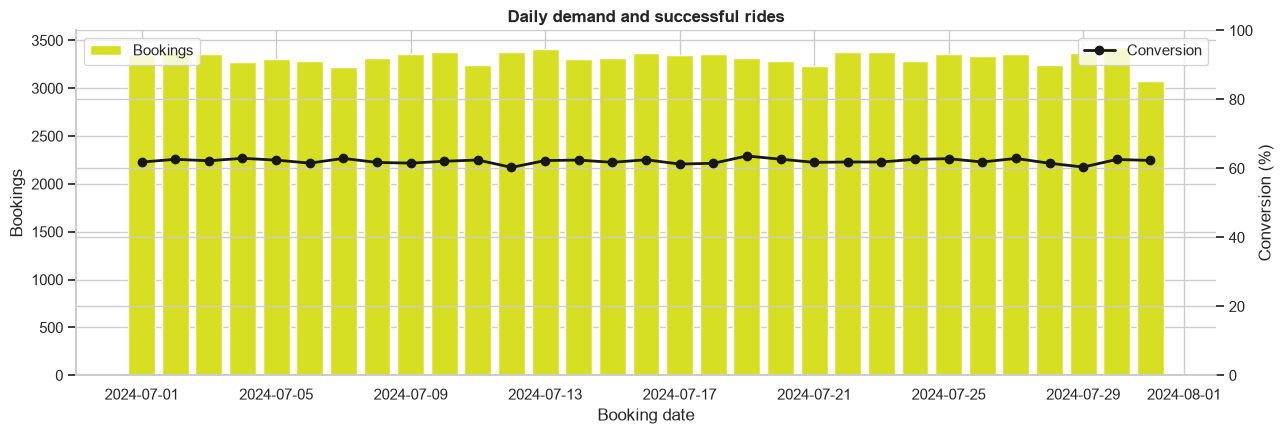

,Bookings,Successful,Conversion (%)
count,31.00,31.00,31.00
mean,3323.35,2063.45,62.09
std,70.34,46.29,0.71
min,3072.00,1914.00,60.29
25%,3287.50,2042.00,61.74
50%,3343.00,2064.00,62.21
75%,3370.50,2092.00,62.61
max,3432.00,2148.00,63.60


,completed_trips,total_completed_distance,average_completed_distance,median_completed_distance
Booking date,,,,
2024-07-01,2072,47540,22.94,21.0
2024-07-02,2122,48434,22.82,21.0
2024-07-03,2089,47156,22.57,21.0
2024-07-04,2060,46280,22.47,20.0
2024-07-05,2063,46711,22.64,21.0
2024-07-06,2019,47258,23.41,22.0
2024-07-07,2027,45550,22.47,20.0
2024-07-08,2045,46346,22.66,21.0
2024-07-09,2066,47168,22.83,21.0


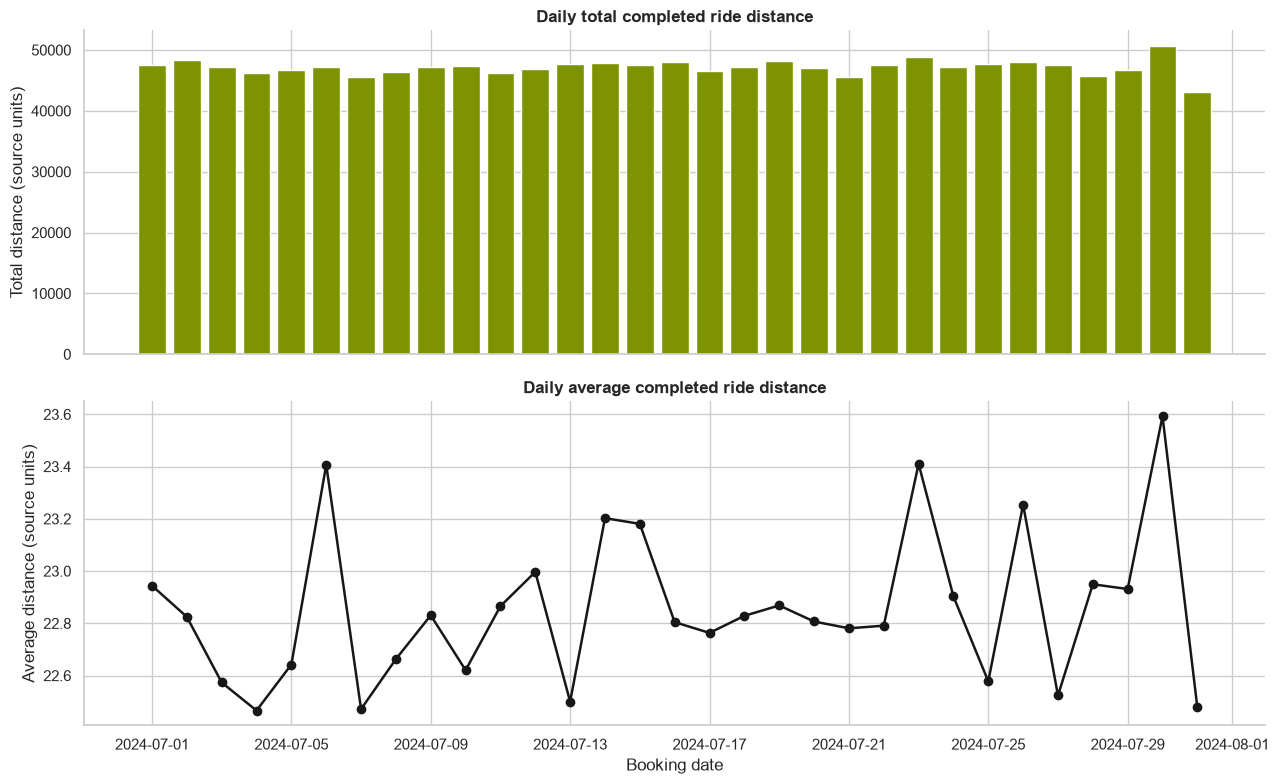

Daily completed-distance averages range from 22.47 to 23.59 source units. Read alongside the daily completed-trip counts.


In [11]:
datetime_col = "Booking DateTime" if "Booking DateTime" in df else None
if datetime_col:
    dated = df.dropna(subset=[datetime_col]).copy()
    dated["Booking Date"] = dated[datetime_col].dt.floor("D")
    daily = dated.groupby("Booking Date").agg(
        Bookings=(datetime_col, "size"),
        Successful=("_status_norm", lambda s: int(s.eq("success").sum())),
    )
    daily["Conversion (%)"] = daily["Successful"] / daily["Bookings"] * 100
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.bar(daily.index, daily["Bookings"], color="#D7DF23", label="Bookings")
    ax.set_ylabel("Bookings")
    ax.set_xlabel("Booking date")
    ax.set_title("Daily demand and successful rides")
    ax2 = ax.twinx()
    ax2.plot(daily.index, daily["Conversion (%)"], color="#171717", marker="o", linewidth=2, label="Conversion")
    ax2.set_ylabel("Conversion (%)")
    ax2.set_ylim(0, 100)
    ax.legend(loc="upper left")
    ax2.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    display(daily.describe().round(2))

# Completed ride-distance distribution per day: cancelled/no-driver rows are not trips.
completed_daily = df.loc[_status_norm.eq("success"), [datetime_col, fields["ride_distance"]]].copy()
completed_daily[datetime_col] = pd.to_datetime(completed_daily[datetime_col], errors="coerce")
completed_daily[fields["ride_distance"]] = pd.to_numeric(completed_daily[fields["ride_distance"]], errors="coerce")
completed_daily = completed_daily.dropna(subset=[datetime_col, fields["ride_distance"]])
assert completed_daily[fields["ride_distance"]].gt(0).all()
completed_daily["Booking date"] = completed_daily[datetime_col].dt.floor("D")
daily_distance = completed_daily.groupby("Booking date")[fields["ride_distance"]].agg(
    completed_trips="count", total_completed_distance="sum",
    average_completed_distance="mean", median_completed_distance="median",
)
display(daily_distance.round(2))
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].bar(daily_distance.index, daily_distance["total_completed_distance"], color="#7D9400")
axes[0].set(title="Daily total completed ride distance", ylabel="Total distance (source units)")
axes[1].plot(daily_distance.index, daily_distance["average_completed_distance"], color="#171717", marker="o", linewidth=1.8)
axes[1].set(title="Daily average completed ride distance", xlabel="Booking date", ylabel="Average distance (source units)")
plt.tight_layout()
plt.show()
print(f"Daily completed-distance averages range from {daily_distance['average_completed_distance'].min():.2f} to {daily_distance['average_completed_distance'].max():.2f} source units. Read alongside the daily completed-trip counts.")

### Completed booking value by payment method and customer

Both analyses use successful bookings only. Payment contribution uses total successful booking value as the denominator. Missing payment methods are retained in an explicit category. Booking value is reported in source units and is not assumed to be recognized revenue.

Completed booking value by payment method (total: 35,080,467 source units)


,successful_bookings,completed_booking_value,share_of_completed_value_pct
_payment,,,
Cash,35022,19260316,54.90
UPI,25881,14168436,40.39
Credit Card,2435,1312793,3.74
Debit Card,629,338922,0.97


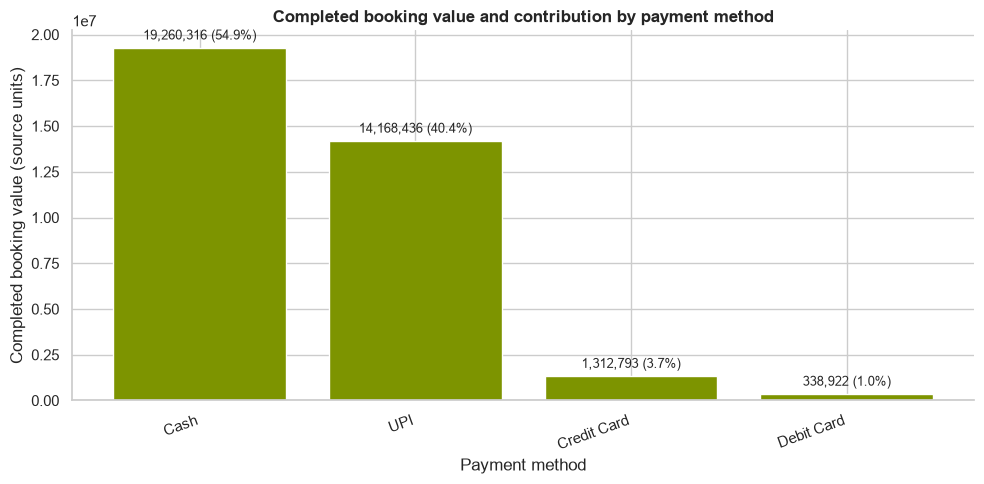

Interpretation: payment mix describes successful bookings only; source units and accounting recognition are not defined.


Successful booking value excluded for missing customer ID: 0 rows


,Completed booking value (source units)
Customer_ID,
CID836942,6019
CID868113,5986
CID695232,5962
CID176493,5944
CID902403,5938


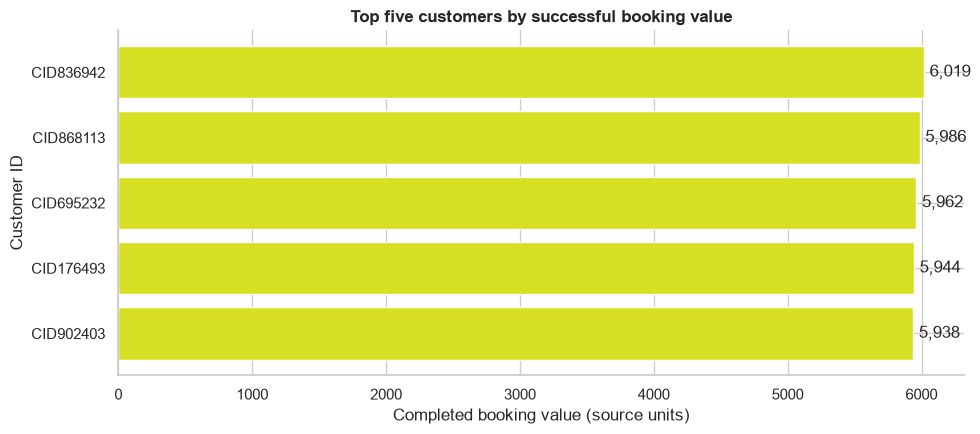

Interpretation: these are booking-value totals for the supplied month, not customer lifetime value or a demographic segment.


In [12]:
success_rows = df.loc[_status_norm.eq("success")].copy()
value_col = fields["booking_value"]
payment_col = fields["payment_method"]
customer_col = fields["customer_id"]
success_rows[value_col] = pd.to_numeric(success_rows[value_col], errors="coerce")

payment_key = success_rows[payment_col].astype("string").str.strip().replace("", pd.NA).fillna("Missing payment method")
payment_revenue = success_rows.assign(_payment=payment_key).groupby("_payment", dropna=False)[value_col].agg(
    successful_bookings="count", completed_booking_value="sum"
).sort_values("completed_booking_value", ascending=False)
payment_total = payment_revenue["completed_booking_value"].sum()
payment_revenue["share_of_completed_value_pct"] = payment_revenue["completed_booking_value"] / payment_total * 100
print(f"Completed booking value by payment method (total: {payment_total:,.0f} source units)")
display(payment_revenue.round(2))
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(payment_revenue.index.astype(str), payment_revenue["completed_booking_value"], color="#7D9400")
ax.bar_label(bars, labels=[f"{v:,.0f} ({s:.1f}%)" for v, s in zip(payment_revenue["completed_booking_value"], payment_revenue["share_of_completed_value_pct"])], padding=4, fontsize=9)
ax.set(title="Completed booking value and contribution by payment method", xlabel="Payment method", ylabel="Completed booking value (source units)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
print("Interpretation: payment mix describes successful bookings only; source units and accounting recognition are not defined.")

customer_value_rows = success_rows.dropna(subset=[customer_col, value_col]).copy()
customer_value_rows[customer_col] = customer_value_rows[customer_col].astype("string").str.strip().replace("", pd.NA)
customer_value_rows = customer_value_rows.dropna(subset=[customer_col])
top5_customer_value = customer_value_rows.groupby(customer_col)[value_col].sum().nlargest(5).sort_values()
print(f"Successful booking value excluded for missing customer ID: {len(success_rows) - len(customer_value_rows):,} rows")
display(top5_customer_value.rename("Completed booking value (source units)").to_frame().sort_values("Completed booking value (source units)", ascending=False))
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(top5_customer_value.index.astype(str), top5_customer_value.values, color="#D7DF23")
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in top5_customer_value.values], padding=4)
ax.set(title="Top five customers by successful booking value", xlabel="Completed booking value (source units)", ylabel="Customer ID")
plt.tight_layout()
plt.show()
print("Interpretation: these are booking-value totals for the supplied month, not customer lifetime value or a demographic segment.")

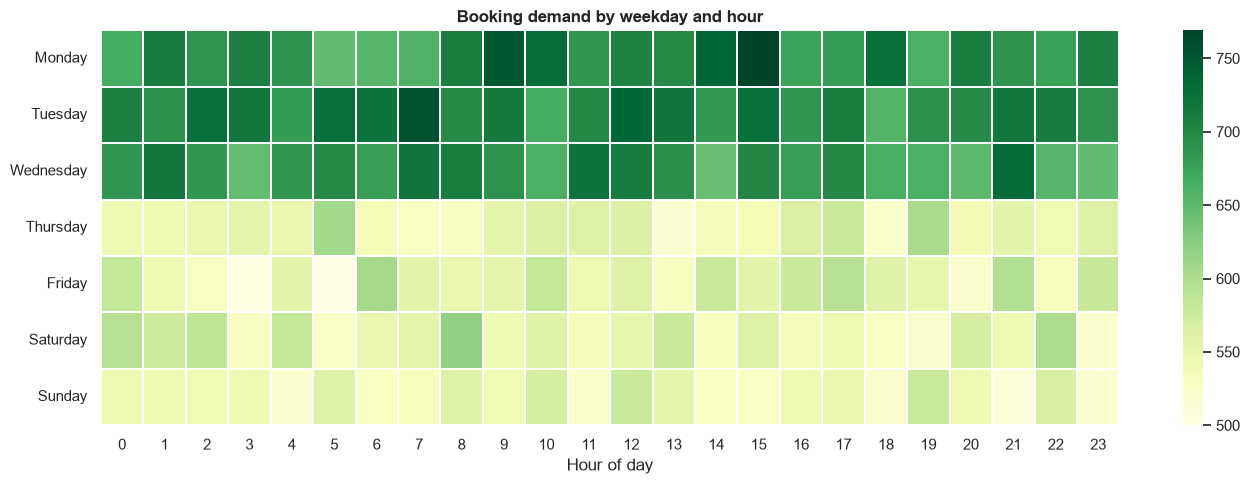

Highest weekday-hour booking cell: Monday at 15:00 (769 bookings).


In [13]:
if "Booking Hour" in df and "Day of Week" in df:
    order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    hour_day = df.pivot_table(index="Day of Week", columns="Booking Hour", values=fields["booking_id"], aggfunc="count", observed=False)
    hour_day = hour_day.reindex(order).fillna(0)
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.heatmap(hour_day, cmap="YlGn", linewidths=.2, ax=ax)
    ax.set(title="Booking demand by weekday and hour", xlabel="Hour of day", ylabel="")
    plt.tight_layout()
    plt.show()
    peak_cell = hour_day.stack().idxmax()
    print(f"Highest weekday-hour booking cell: {peak_cell[0]} at {peak_cell[1]:02d}:00 ({hour_day.loc[peak_cell[0], peak_cell[1]]:,.0f} bookings).")

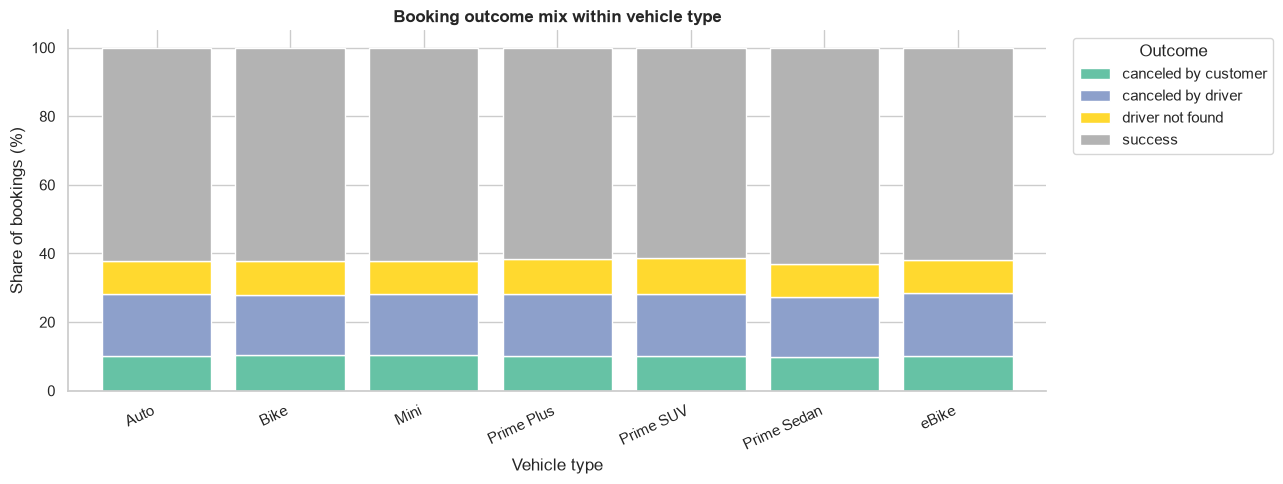

_status_norm,canceled by customer,canceled by driver,driver not found,success,Total
Vehicle_Type,,,,,
Auto,1503,2675,1410,9167,14755
Bike,1537,2559,1432,9134,14662
Mini,1505,2584,1427,9036,14552
Prime Plus,1474,2683,1475,9075,14707
Prime SUV,1498,2648,1513,8996,14655
Prime Sedan,1470,2591,1437,9379,14877
eBike,1512,2694,1430,9180,14816


In [14]:
# Outcome mix by vehicle: within-vehicle percentages prevent volume alone from driving the comparison.
if vehicle_col:
    outcome_mix = pd.crosstab(df[vehicle_col], df["_status_norm"], normalize="index") * 100
    outcome_mix = outcome_mix.sort_index()
    ax = outcome_mix.plot(kind="bar", stacked=True, figsize=(13, 5), colormap="Set2", width=.82)
    ax.set(title="Booking outcome mix within vehicle type", xlabel="Vehicle type", ylabel="Share of bookings (%)")
    ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    display((pd.crosstab(df[vehicle_col], df["_status_norm"]).assign(Total=lambda x: x.sum(axis=1))))

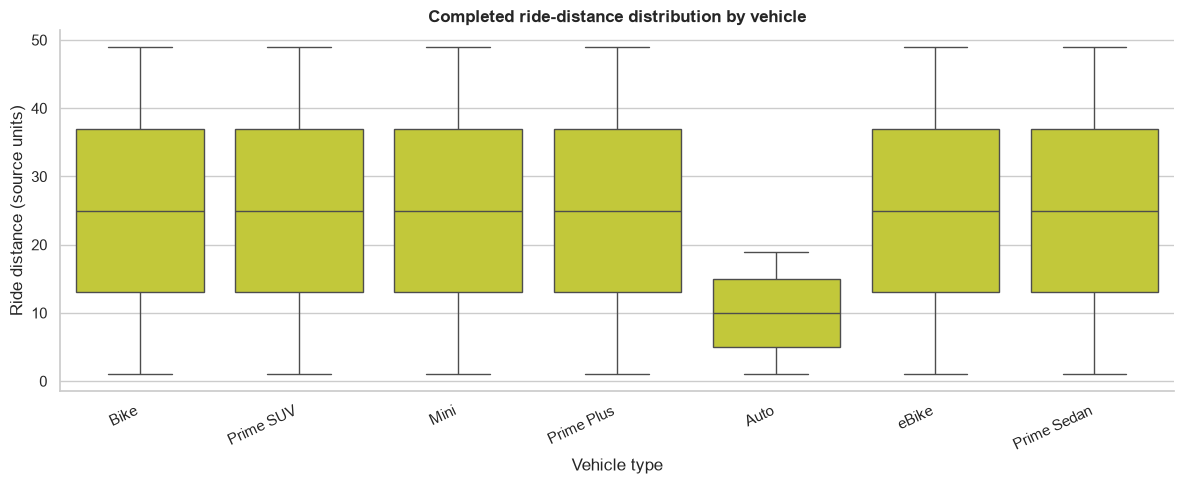

,completed_trips,mean,median,total_completed_distance
Vehicle_Type,,,,
Prime Sedan,9379,25.01,25.0,234535
eBike,9180,25.15,25.0,230842
Bike,9134,24.93,25.0,227746
Prime Plus,9075,25.03,25.0,227186
Mini,9036,24.98,25.0,225703
Prime SUV,8996,24.88,25.0,223848
Auto,9167,10.04,10.0,92043


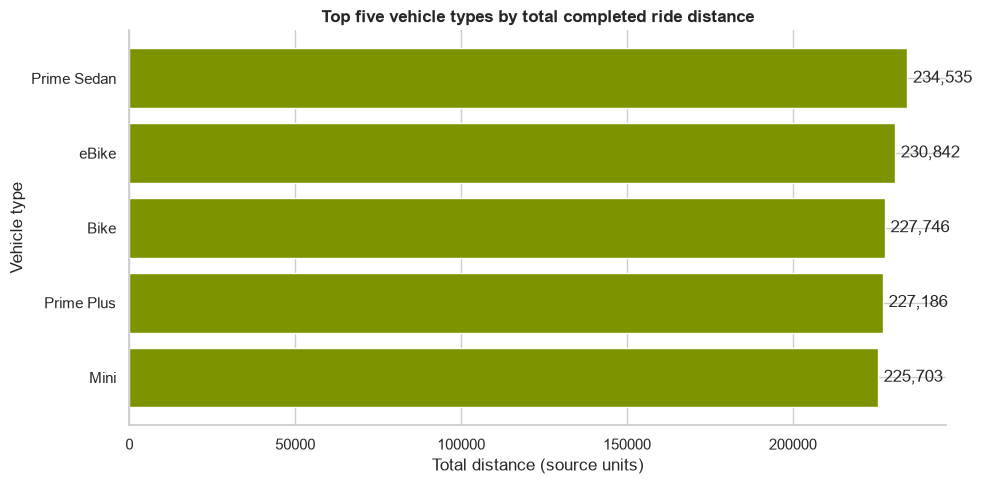

Interpretation: totals combine successful-trip volume and trip length; use the trip count and median distance alongside the ranking.


In [15]:
# Compare completed-trip distance only; all zero-distance unsuccessful rows stay in df for other analyses.
if vehicle_col and distance_col:
    plot_df = df.loc[_status_norm.eq("success"), [vehicle_col, distance_col]].copy()
    plot_df[distance_col] = pd.to_numeric(plot_df[distance_col], errors="coerce")
    plot_df = plot_df.dropna(subset=[vehicle_col, distance_col])
    assert plot_df[distance_col].gt(0).all()

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.boxplot(data=plot_df, x=vehicle_col, y=distance_col, showfliers=False, ax=ax, color="#D7DF23")
    ax.set(title="Completed ride-distance distribution by vehicle", xlabel="Vehicle type", ylabel="Ride distance (source units)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

    vehicle_distance = plot_df.groupby(vehicle_col)[distance_col].agg(
        completed_trips="count", mean="mean", median="median", total_completed_distance="sum"
    ).sort_values("total_completed_distance", ascending=False)
    display(vehicle_distance.round(2))

    top5_distance = vehicle_distance.head(5).sort_values("total_completed_distance")
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(top5_distance.index.astype(str), top5_distance["total_completed_distance"], color="#7D9400")
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in top5_distance["total_completed_distance"]], padding=4)
    ax.set(title="Top five vehicle types by total completed ride distance", xlabel="Total distance (source units)", ylabel="Vehicle type")
    plt.tight_layout()
    plt.show()
    print("Interpretation: totals combine successful-trip volume and trip length; use the trip count and median distance alongside the ranking.")

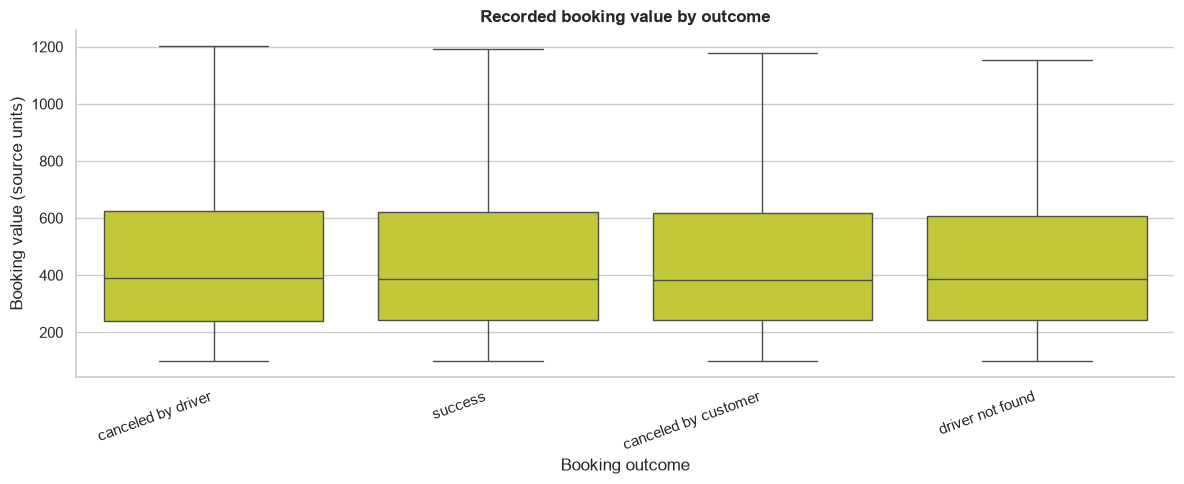

,records,median,mean
_status_norm,,,
canceled by customer,10499,384.0,549.66
canceled by driver,18434,389.0,552.43
driver not found,10124,387.0,543.25
success,63967,385.0,548.42


In [16]:
# Booking value by outcome. This is the source booking measure, not audited revenue.
if value_col:
    plot_df = df[["_status_norm", value_col]].dropna()
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.boxplot(data=plot_df, x="_status_norm", y=value_col, showfliers=False, ax=ax, color="#D7DF23")
    ax.set(title="Recorded booking value by outcome", xlabel="Booking outcome", ylabel="Booking value (source units)")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
    display(plot_df.groupby("_status_norm")[value_col].agg(records="count", median="median", mean="mean").round(2))

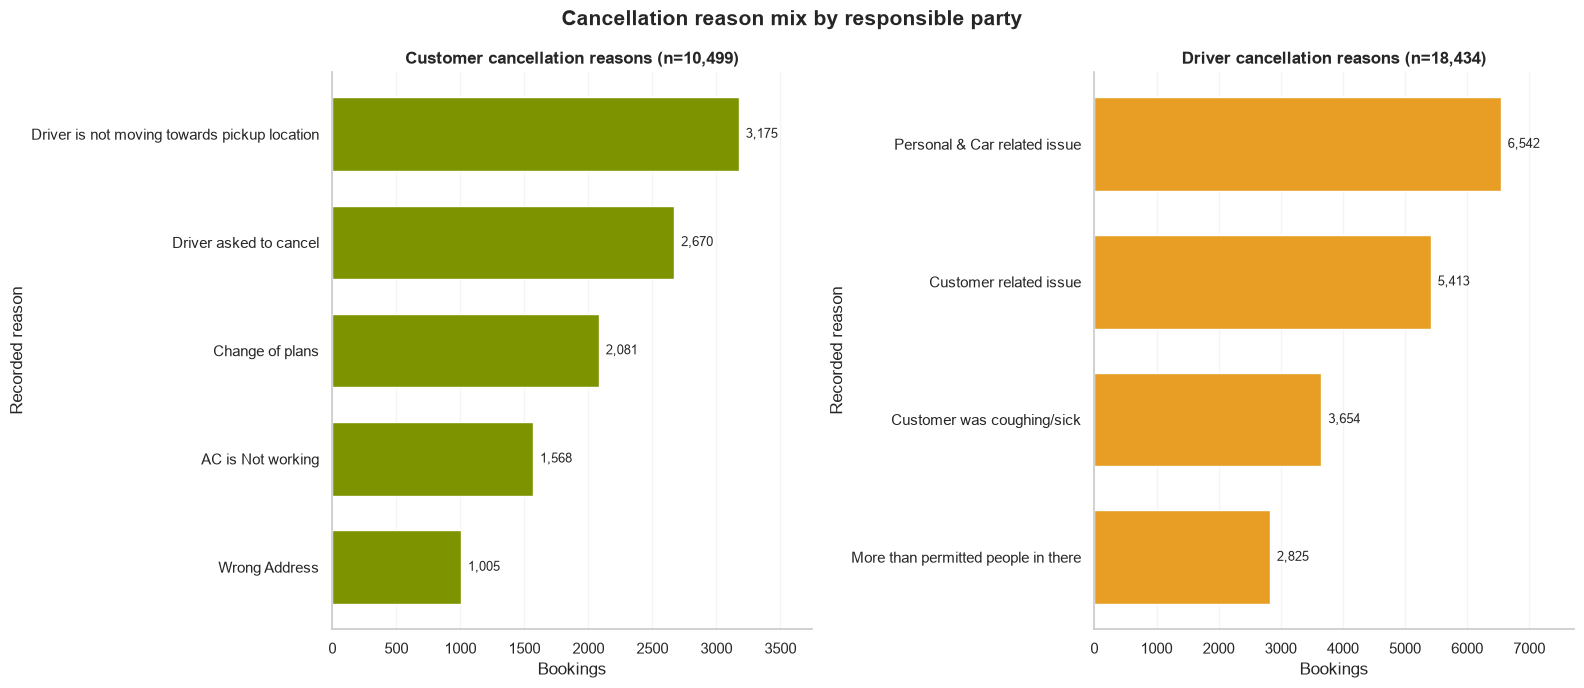

,Outcome,Bookings,With recorded reason,Coverage (%)
0,Canceled By Customer,10499,10499,100.0
1,Canceled By Driver,18434,18434,100.0


In [17]:
# Compare reasons only inside the matching cancellation outcome. These mapping keys
# match the source-field resolver in src/ola_ride_insights/pipeline.py.
reason_specs = [
    ("canceled by customer", "customer_cancel_reason", "Customer cancellation reasons"),
    ("canceled by driver", "driver_cancel_reason", "Driver cancellation reasons"),
]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (outcome, key, title) in zip(axes, reason_specs):
    reason_col = fields.get(key)
    if not reason_col or reason_col not in df.columns:
        ax.text(.5, .5, f"Source field unavailable: {key}", ha="center", va="center", wrap=True)
        ax.set_axis_off()
        continue

    mask = df["_status_norm"].eq(outcome)
    reasons = df.loc[mask, reason_col].astype("string").str.strip()
    reasons = reasons[reasons.notna() & reasons.ne("")]
    counts = reasons.value_counts().sort_values()
    if counts.empty:
        ax.text(.5, .5, f"No recorded reasons for {outcome}", ha="center", va="center", wrap=True)
        ax.set_axis_off()
        continue

    color = "#7D9400" if outcome == "canceled by customer" else "#E89E25"
    bars = ax.barh(counts.index.astype(str), counts.values, color=color, height=.68)
    ax.bar_label(bars, labels=[f"{value:,}" for value in counts.values], padding=5, fontsize=9)
    ax.set_xlim(0, counts.max() * 1.18)
    ax.set(title=f"{title} (n={int(counts.sum()):,})", xlabel="Bookings", ylabel="Recorded reason")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", alpha=.2)
    ax.set_axisbelow(True)

fig.suptitle("Cancellation reason mix by responsible party", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Make the coverage visible so missing or mis-mapped reasons cannot pass silently.
reason_coverage = []
for outcome, key, _ in reason_specs:
    reason_col = fields.get(key)
    mask = df["_status_norm"].eq(outcome)
    recorded = int(df.loc[mask, reason_col].astype("string").str.strip().replace("", pd.NA).notna().sum()) if reason_col and reason_col in df else 0
    reason_coverage.append({"Outcome": outcome.title(), "Bookings": int(mask.sum()), "With recorded reason": recorded, "Coverage (%)": 100 * recorded / max(int(mask.sum()), 1)})
display(pd.DataFrame(reason_coverage).round(1))

,Vehicle,Customer mean,Customer n,Driver mean,Driver n
3,Prime Plus,4.01,9075,4.00,9075
5,Prime Sedan,4.00,9379,3.99,9379
4,Prime SUV,4.00,8996,4.01,8996
0,Auto,4.00,9167,4.00,9167
2,Mini,4.00,9036,3.99,9036
1,Bike,3.99,9134,3.98,9134
6,eBike,3.99,9180,4.01,9180


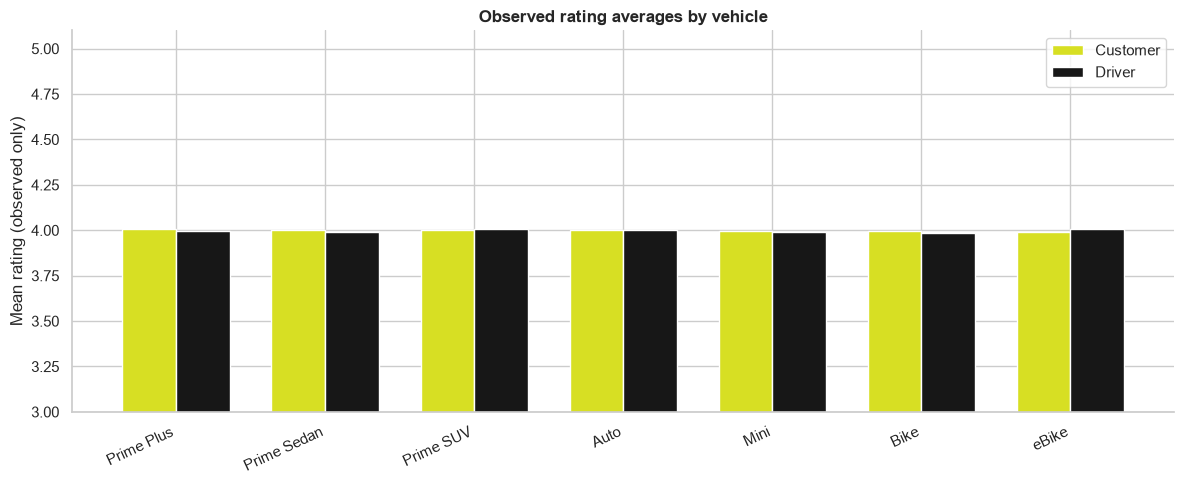

In [18]:
# Rating averages always include observed feedback counts alongside the mean.
if vehicle_col and customer_rating_col and driver_rating_col:
    rows = []
    for vehicle_name, group in df.groupby(vehicle_col, dropna=False):
        c = pd.to_numeric(group[customer_rating_col], errors="coerce")
        d = pd.to_numeric(group[driver_rating_col], errors="coerce")
        rows.append({"Vehicle": vehicle_name, "Customer mean": c.mean(), "Customer n": c.notna().sum(),
                     "Driver mean": d.mean(), "Driver n": d.notna().sum()})
    ratings_by_vehicle = pd.DataFrame(rows).sort_values("Customer mean", ascending=False)
    display(ratings_by_vehicle.round(2))
    fig, ax = plt.subplots(figsize=(12, 5))
    positions = np.arange(len(ratings_by_vehicle))
    ax.bar(positions - .18, ratings_by_vehicle["Customer mean"], width=.36, label="Customer", color="#D7DF23")
    ax.bar(positions + .18, ratings_by_vehicle["Driver mean"], width=.36, label="Driver", color="#171717")
    ax.set_xticks(positions, ratings_by_vehicle["Vehicle"], rotation=25, ha="right")
    ax.set(ylim=(3, 5.1), title="Observed rating averages by vehicle", ylabel="Mean rating (observed only)")
    ax.legend()
    plt.tight_layout()
    plt.show()

Paired feedback: 63,967 trips (62.1% of bookings); exact agreement: 4.9%; Pearson r: -0.003.


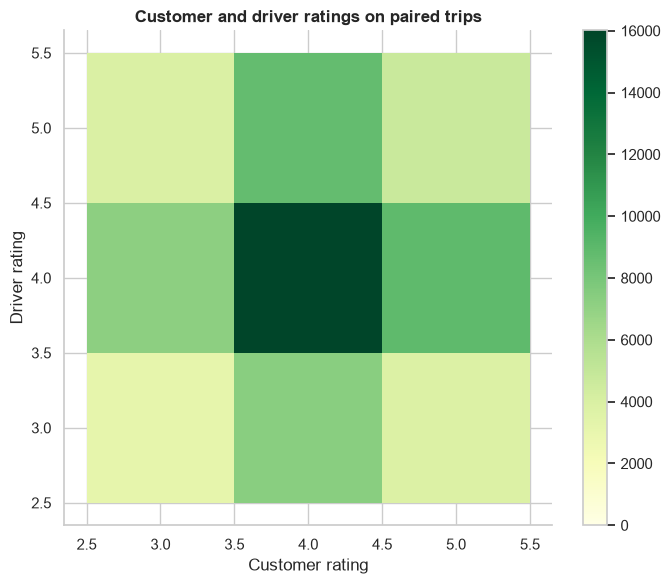

Agreement and correlation are descriptive; neither rater is treated as the ground truth.


In [19]:
# Paired-rating relationship: plot density rather than overplotting every trip.
if customer_rating_col and driver_rating_col:
    pairs = df[[customer_rating_col, driver_rating_col]].apply(pd.to_numeric, errors="coerce").dropna()
    exact_agreement = (pairs[customer_rating_col] == pairs[driver_rating_col]).mean() if len(pairs) else np.nan
    correlation = pairs[customer_rating_col].corr(pairs[driver_rating_col]) if len(pairs) > 1 else np.nan
    print(f"Paired feedback: {len(pairs):,} trips ({len(pairs)/len(df):.1%} of bookings); exact agreement: {exact_agreement:.1%}; Pearson r: {correlation:.3f}.")
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.histplot(data=pairs, x=customer_rating_col, y=driver_rating_col, discrete=(True, True), cbar=True, ax=ax, cmap="YlGn")
    ax.set(title="Customer and driver ratings on paired trips", xlabel="Customer rating", ylabel="Driver rating")
    plt.tight_layout()
    plt.show()
    print("Agreement and correlation are descriptive; neither rater is treated as the ground truth.")

### 6.3 Multivariate | Combined operating signals

Combine relevant dimensions to reveal where demand and service outcomes meet. Do not interpret cell concentration as a causal effect or compare groups without considering volume.

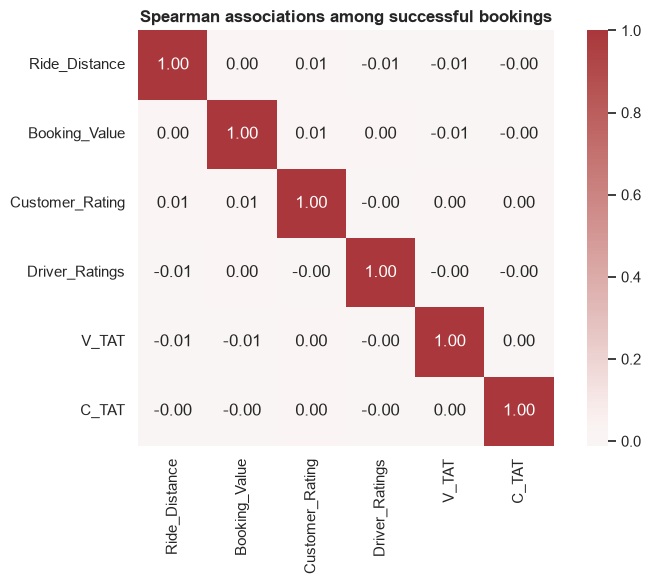

,count,mean,std,min,25%,50%,75%,max
Ride_Distance,63967.0,22.85,14.24,1.0,10.0,21.0,35.0,49.0
Booking_Value,63967.0,548.42,536.65,100.0,242.0,385.0,622.0,2999.0
Customer_Rating,63967.0,4.00,0.58,3.0,3.5,4.0,4.5,5.0
Driver_Ratings,63967.0,4.00,0.58,3.0,3.5,4.0,4.5,5.0
V_TAT,63967.0,170.88,80.80,35.0,98.0,168.0,238.0,308.0
C_TAT,63967.0,84.87,36.01,25.0,55.0,85.0,115.0,145.0


TAT fields retain missing values; correlation is pairwise-complete and does not assign causal meaning.


In [20]:
# Numeric associations are descriptive and use successful-trip records for distance.
numeric_keys = ["ride_distance", "booking_value", "customer_rating", "driver_rating", "v_tat", "c_tat"]
numeric_cols = [fields[key] for key in numeric_keys if fields.get(key)]
completed_numeric = df.loc[_status_norm.eq("success"), numeric_cols].apply(pd.to_numeric, errors="coerce")
correlation_matrix = completed_numeric.corr(method="spearman", min_periods=100)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", center=0, cmap="vlag", square=True, ax=ax)
ax.set(title="Spearman associations among successful bookings")
plt.tight_layout()
plt.show()
display(completed_numeric.describe().T.round(2))
print("TAT fields retain missing values; correlation is pairwise-complete and does not assign causal meaning.")

,Bookings,Successes,DriverNotFound,DriverCancellations,Success rate (%),Supply-loss rate (%)
Booking Hour,,,,,,
0,4318,2726,434,757,63.1,27.6
1,4329,2697,442,762,62.3,27.8
2,4305,2658,445,782,61.7,28.5
3,4201,2668,389,737,63.5,26.8
4,4263,2651,382,800,62.2,27.7
5,4264,2710,383,752,63.6,26.6
6,4271,2655,417,747,62.2,27.3
7,4304,2628,432,777,61.1,28.1
8,4374,2681,445,812,61.3,28.7


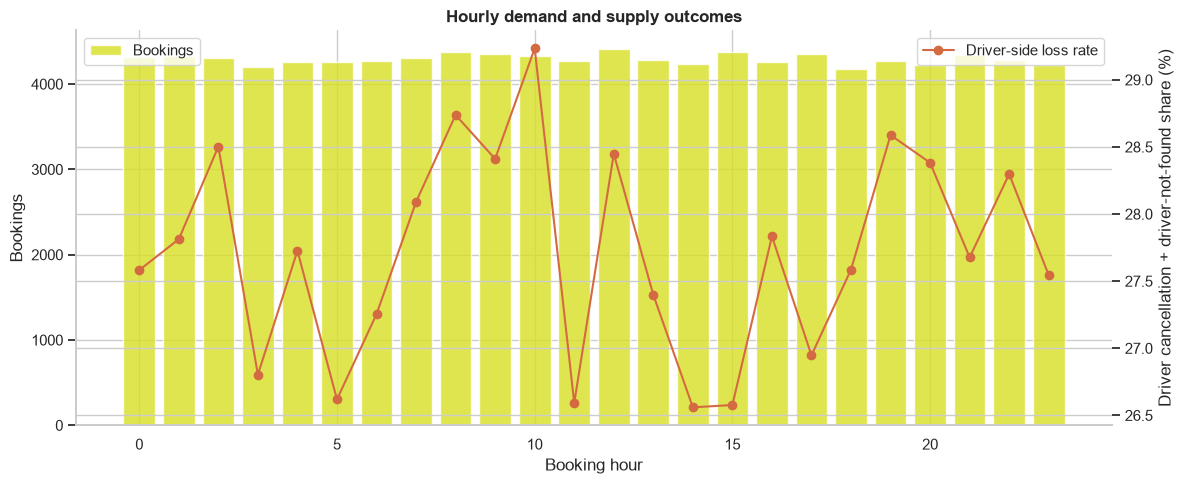

Hour with highest observed driver-side loss share: 10:00 (29.2%, 4,334 bookings). Review volume and pickup context before changing allocation.


In [21]:
# Demand-loss grid: counts and rates together prevent small groups from looking equally important.
if "Booking Hour" in df:
    hourly = df.groupby("Booking Hour").agg(
        Bookings=("_status_norm", "size"),
        Successes=("_status_norm", lambda s: int(s.eq("success").sum())),
        DriverNotFound=("_status_norm", lambda s: int(s.eq("driver not found").sum())),
        DriverCancellations=("_status_norm", lambda s: int(s.eq("canceled by driver").sum())),
    )
    hourly["Success rate (%)"] = hourly["Successes"] / hourly["Bookings"] * 100
    hourly["Supply-loss rate (%)"] = (hourly["DriverNotFound"] + hourly["DriverCancellations"]) / hourly["Bookings"] * 100
    display(hourly.round(1))
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(hourly.index, hourly["Bookings"], color="#D7DF23", alpha=.8, label="Bookings")
    ax.set(xlabel="Booking hour", ylabel="Bookings", title="Hourly demand and supply outcomes")
    ax2 = ax.twinx()
    ax2.plot(hourly.index, hourly["Supply-loss rate (%)"], color="#D46A42", marker="o", label="Driver-side loss rate")
    ax2.set_ylabel("Driver cancellation + driver-not-found share (%)")
    ax.legend(loc="upper left")
    ax2.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    peak_loss_hour = hourly["Supply-loss rate (%)"].idxmax()
    print(f"Hour with highest observed driver-side loss share: {peak_loss_hour:02d}:00 ({hourly.loc[peak_loss_hour, 'Supply-loss rate (%)']:.1f}%, {hourly.loc[peak_loss_hour, 'Bookings']:,} bookings). Review volume and pickup context before changing allocation.")

,Driver-not-found bookings,Share
Pickup area,,
Hennur,228,2.3%
Marathahalli,225,2.2%
Mysore Road,220,2.2%
Peenya,220,2.2%
Hosur Road,219,2.2%
Cox Town,218,2.2%
Sahakar Nagar,218,2.2%
Kengeri,217,2.1%
Kammanahalli,215,2.1%


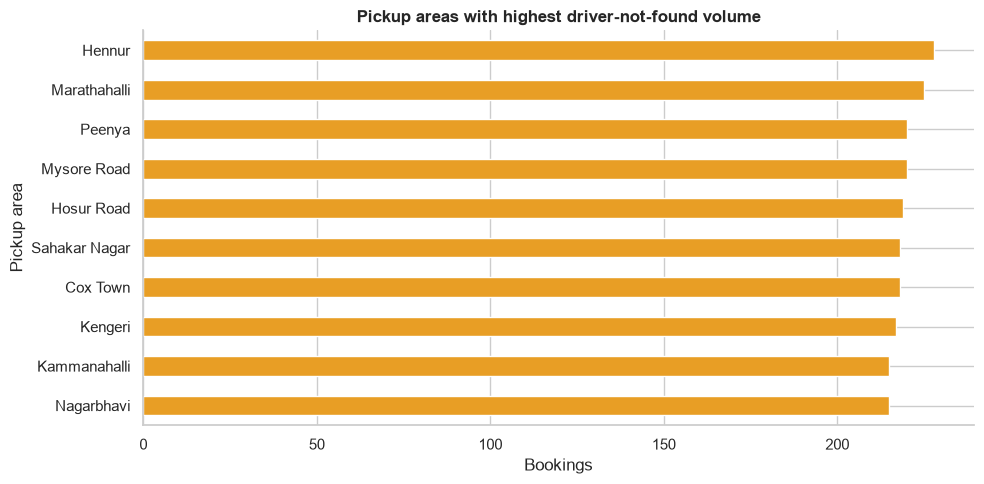

In [22]:
# Pickup concentration among driver-not-found outcomes; report counts, not just relative rank.
pickup_col = fields.get("pickup_location")
if pickup_col:
    unmatched = df.loc[is_driver_not_found, pickup_col].fillna("Missing pickup")
    pickup_summary = unmatched.value_counts().head(10).rename_axis("Pickup area").to_frame("Driver-not-found bookings")
    pickup_summary["Share of driver-not-found"] = pickup_summary["Driver-not-found bookings"] / max(int(is_driver_not_found.sum()), 1)
    display(pickup_summary.assign(Share=lambda x: (x["Share of driver-not-found"] * 100).round(1).astype(str) + "%").drop(columns="Share of driver-not-found"))
    ax = pickup_summary["Driver-not-found bookings"].sort_values().plot.barh(figsize=(10, 5), color="#E89E25")
    ax.set(title="Pickup areas with highest driver-not-found volume", xlabel="Bookings", ylabel="Pickup area")
    plt.tight_layout()
    plt.show()

## 7. Findings, actions and limitations

### Evidence-based operating readout

Use the computed cells above to prioritize only what the source supports:

1. **Supply fulfillment:** inspect driver cancellations and driver-not-found bookings separately; use hour and pickup-area concentration to identify candidate dispatch reviews.
2. **Conversion:** track successful rides against all bookings and monitor the separate loss categories after any operational change.
3. **Vehicle mix:** compare trip volume, total distance and median distance together; total distance alone combines fleet mix and trip length.
4. **Customer experience:** compare rating averages with observed-feedback counts and paired-feedback coverage; do not treat missing ratings as zero.
5. **Value:** report completed booking value only for successful trips and label it in source units until finance confirms currency and recognition rules.

### Limitations and next data requests

- One month (July 2024) supports a baseline but not seasonality, trend or intervention evaluation.
- No surge flag or fare components means surge effectiveness and pricing fairness cannot be estimated.
- No costs, driver hours, vehicle availability, margin or customer demographics means profitability, productivity and customer segmentation claims are out of scope.
- Distance and turnaround-time units/definitions are not specified. Confirm them with the source owner before benchmarking.
- Statistical outlier flags are prompts for record-level review, not fraud labels.
- For causal or board-level decisions, obtain multiple comparable months, supply-hours and dispatch data, audited currency definitions, and a documented metric owner.

### Reproducible handoff

The raw workbook remains unchanged. Cleaning logic is shared with the application in `src/ola_ride_insights/pipeline.py`; processed output and QA artifacts are produced by the pipeline. Re-run the notebook from the project root after source refresh and compare the same metric definitions before communicating changes.